# Contre-mesure : comparaison à temps constant (démonstration)

**Projet Embedded Security, Ibrahim Amghar**

L'attaque SPA exploitait une seule faiblesse du firmware : la comparaison du mot de passe s'arrêtait au premier caractère faux (`early_exit_compare`). Le nombre d'itérations dépendait donc du mot de passe, ce qui créait la fuite visible sur la trace.

### La contre-mesure

On remplace la comparaison par une version à temps constant : elle regarde toujours les 8 caractères, compte ceux qui sont corrects, et n'accepte que si les 8 le sont. Elle ne s'arrête jamais en avance.

```c
bool constant_time_compare(const char *attempt) {
  size_t pass_len = sizeof(PASSWORD) - 1;   // 8 caracteres
  int nb_corrects = 0;
  for (size_t i = 0; i < pass_len; ++i) {
    if (attempt[i] == PASSWORD[i]) {
      nb_corrects = nb_corrects + 1;        // on compte les bons caracteres
    }
  }
  return (nb_corrects == pass_len);          // vrai seulement si les 8 sont bons
}
```

Comme la boucle fait toujours 8 tours, sa durée ne dépend plus du mot de passe, donc la fuite temporelle exploitée par la SPA disparaît.

### But de ce notebook

Montrer que sur le firmware durci, la fuite d'avant n'existe plus : mêmes captures, même méthode que le notebook d'attaque, mais le mot de passe n'est plus récupérable. L'étape d'exploitation n'a donc plus lieu d'être.

## 1. Connexion et fonctions de capture

Le montage et le code de capture sont identiques au notebook d'attaque, c'est important pour que la comparaison soit honnête. Seul le firmware de la cible a changé (comparaison à temps constant au lieu de l'early-exit).

In [1]:
import chipwhisperer as cw
import time

# on se connecte au scope (la ChipWhisperer) et a la cible (l'Arduino)
scope = cw.scope()
scope.default_setup()
scope.adc.samples = 3000          # nombre de points par trace

target = cw.target(scope, cw.targets.SimpleSerial2)
target.baud = 9600                # debit de l'entree cachee (D10/D11)

print("Connecte au coffre.")

(ChipWhisperer Other WARNING|File __init__.py:69) ChipWhisperer update available! See https://chipwhisperer.readthedocs.io/en/latest/installing.html for updating instructions


Connecte au coffre.


In [2]:
def capturer_une_trace(essai):
    # 1) on vide ce qui traine dans le buffer serie
    restant = target.in_waiting()
    while restant > 0:
        target.read(restant, 10)
        time.sleep(0.01)
        restant = target.in_waiting()

    # 2) on arme le scope, on envoie l'essai, on capture
    scope.arm()
    target.write(essai)
    timeout = scope.capture()
    if timeout:
        print("Timeout : le trigger ne s'est pas declenche")

    # 3) on recupere la trace et on lit la reponse du coffre
    trace = scope.get_last_trace()
    target.read(300, 10)
    return trace

In [3]:
def capturer_moyenne(essai, nombre):
    # on capture "nombre" fois le meme essai et on fait la moyenne
    total = capturer_une_trace(essai)
    for i in range(nombre - 1):
        time.sleep(0.01)          # petite pause pour ne pas saturer l'USB
        total = total + capturer_une_trace(essai)
    moyenne = total / nombre
    return moyenne

La cellule de connexion doit afficher `Connecte au coffre.` et aucune capture ne doit
déclencher de *Timeout*. Le trigger (broche D13) est inchangé dans le firmware durci.


## 2. La fuite a-t-elle disparu ? (test visuel)

On refait le même overlay que dans le notebook d'attaque : un bon premier caractère (`f`) contre un mauvais (`a`). Sur le firmware vulnérable, les deux traces divergeaient nettement vers l'échantillon 128. Sur le durci, elles doivent rester superposées.

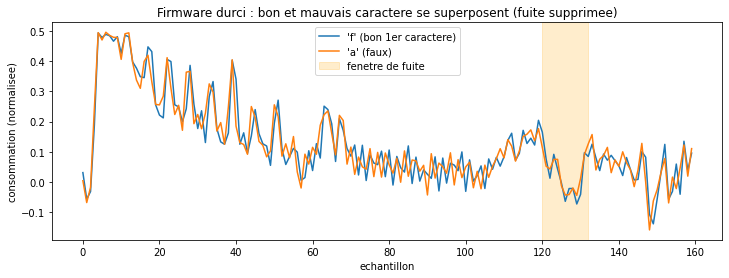

In [15]:
import matplotlib.pyplot as plt

bon  = capturer_moyenne("f\n", 20)
faux = capturer_moyenne("a\n", 20)

plt.figure(figsize=(12, 4))
plt.plot(bon[:160],  label="'f' (bon 1er caractere)")
plt.plot(faux[:160], label="'a' (faux)")
plt.axvspan(120, 132, color="orange", alpha=0.2, label="fenetre de fuite")
plt.title("Firmware durci : bon et mauvais caractere se superposent (fuite supprimee)")
plt.xlabel("echantillon")
plt.ylabel("consommation (normalisee)")
plt.legend()
plt.show()

Les deux traces se suivent sur toute la longueur, y compris dans l'ancienne fenêtre de fuite (en orange). Le décrochage vers l'échantillon 128 a disparu : le bon et le mauvais caractère consomment maintenant la même chose.

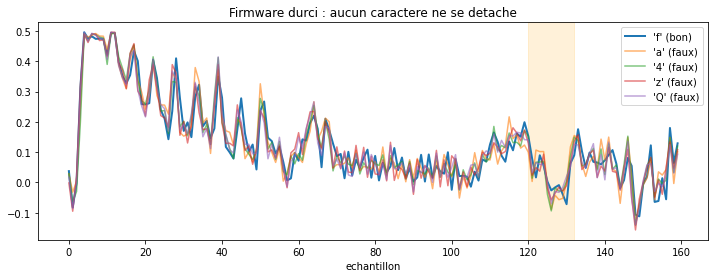

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(capturer_moyenne("f\n", 20)[:160], label="'f' (bon)", linewidth=2)
for c in ["a", "4", "z", "Q"]:
    plt.plot(capturer_moyenne(c + "\n", 20)[:160], alpha=0.6, label=f"'{c}' (faux)")
plt.axvspan(120, 132, color="orange", alpha=0.15)
plt.title("Firmware durci : aucun caractere ne se detache")
plt.xlabel("echantillon")
plt.legend()
plt.show()

Même en empilant plusieurs mauvais caractères avec le bon, toutes les courbes se
confondent, y compris dans l'ancienne zone de fuite. Aucun caractère ne ressort, il n'y a
plus rien à exploiter.


## 3. Confirmation quantitative : score des 94 candidats

Le test visuel est parlant, on le confirme avec la métrique de l'attaque. On calcule, pour la position 0, le score (écart à la moyenne) des 94 candidats. Sur le firmware vulnérable, le bon caractère (`f`) sortait détaché avec une marge d'environ x3.3. Sur le durci, aucun candidat ne devrait se détacher : la marge doit tomber vers x1.0.

In [17]:
import numpy as np

# tous les caracteres imprimables (ASCII 33 a 126)
candidats = [chr(code) for code in range(33, 127)]

def tester_position(connus, debut, fin, nombre):
    # connus = le debut du mot de passe deja trouve (ex: "f7")
    # debut, fin = la fenetre ou regarder la fuite
    # nombre = combien de moyennes par caractere

    # 1) une trace moyennee par caractere candidat
    traces = {}
    for c in candidats:
        essai = connus + c + "\n"
        traces[c] = capturer_moyenne(essai, nombre)

    # 2) la trace moyenne de TOUS les caracteres = le comportement "faux"
    liste = []
    for c in candidats:
        liste.append(traces[c])
    toutes = np.array(liste)
    moyenne = toutes.mean(axis=0)

    # 3) pour chaque caractere, on mesure l'ecart a la moyenne dans la fenetre
    scores = {}
    for c in candidats:
        difference = np.abs(traces[c][debut:fin] - moyenne[debut:fin])
        scores[c] = np.sum(difference)

    # 4) on classe du plus gros ecart au plus petit
    classement = sorted(scores, key=scores.get, reverse=True)
    return classement, scores

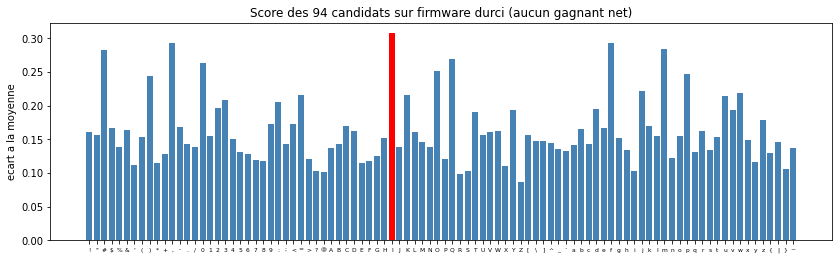

In [18]:
classement, scores = tester_position("", 120, 132, 25)

# scores dans l'ordre alphabetique des candidats, gagnant en rouge
valeurs = [scores[c] for c in candidats]
couleurs = ["red" if c == classement[0] else "steelblue" for c in candidats]

plt.figure(figsize=(14, 4))
plt.bar(range(len(candidats)), valeurs, color=couleurs)
plt.xticks(range(len(candidats)), candidats, fontsize=6)
plt.title(f"Score des 94 candidats sur firmware durci (aucun gagnant net)")
plt.ylabel("ecart a la moyenne")
plt.show()

In [8]:
# resume chiffre : le meilleur candidat se detache-t-il encore ?
marge = scores[classement[0]] / scores[classement[1]]
print("Top 5 (firmware durci) :")
for c in classement[:5]:
    print(" ", repr(c), round(scores[c], 2))
print()
print("marge (1er / 2e) : x", round(marge, 2))
print("(pour rappel, sur le firmware vulnerable : x3.3)")


Top 5 (firmware durci) :
  '<' 0.28
  '6' 0.26
  '+' 0.26
  '#' 0.25
  '=' 0.23

marge (1er / 2e) : x 1.06
(pour rappel, sur le firmware vulnerable : x3.3)


Les 94 barres sont au même niveau, aucune ne domine, et la marge retombe autour de x1.0
(contre x3.3 sur le firmware vulnérable). Le « gagnant » affiché n'est que du bruit : il
change à chaque exécution et ne veut rien dire. La métrique confirme l'absence de fuite.


## 4. L'attaque complète échoue (test long)

Pour aller au bout de la démonstration, on relance l'attaque complète sur les 8 positions. Attendu : des marges toutes proches de x1.0 (bien en dessous du seuil de fiabilité x1.3) et un mot de passe final faux.

position 0 : 'Z' - marge x 1.1
position 1 : '7' - marge x 1.1
position 2 : '-' - marge x 1.3
position 3 : '@' - marge x 1.4
position 4 : 'J' - marge x 2.2
position 5 : 'f' - marge x 1.1
position 6 : '1' - marge x 1.0
position 7 : '!' - marge x 1.1
Mot de passe : 'Z7-@Jf1!'


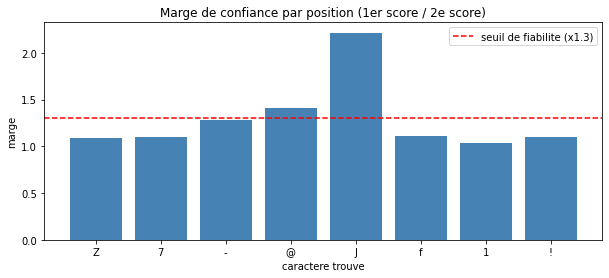

In [9]:
mot_de_passe = ""
nombre = 25
marges = []

while len(mot_de_passe) < 8:
    position = len(mot_de_passe)
    debut = 120 + 7 * position
    fin = debut + 12
    classement, scores = tester_position(mot_de_passe, debut, fin, nombre)
    gagnant = classement[0]
    marge = scores[classement[0]] / scores[classement[1]]
    marges.append(marge)
    print("position", position, ":", repr(gagnant), "- marge x", round(marge, 1))
    mot_de_passe = mot_de_passe + gagnant

print("Mot de passe :", repr(mot_de_passe))

# la figure
plt.figure(figsize=(10, 4))
plt.bar(range(8), marges, color="steelblue")
plt.axhline(1.3, color="red", linestyle="--", label="seuil de fiabilite (x1.3)")
plt.xticks(range(8), list(mot_de_passe))
plt.title("Marge de confiance par position (1er score / 2e score)")
plt.xlabel("caractere trouve")
plt.ylabel("marge")
plt.legend()
plt.show()

Les marges restent collées à x1.0 à chaque position et le mot de passe reconstruit est
incorrect. L'attaque qui réussissait sur le firmware vulnérable échoue ici.


## 5. La contre-mesure ne casse pas la fonctionnalité

Durcir la comparaison ne doit pas empêcher un utilisateur légitime d'entrer. On envoie le vrai mot de passe et on vérifie que le coffre s'ouvre toujours.

In [14]:
# la contre-mesure ne casse pas la fonctionnalite :
# le BON mot de passe ouvre toujours le coffre

# on vide le buffer serie pour ne pas melanger avec les reponses precedentes
restant = target.in_waiting()
while restant > 0:
    target.read(restant, 10)
    time.sleep(0.01)
    restant = target.in_waiting()

# on envoie le vrai mot de passe et on lit la reponse complete
scope.arm()
target.write("f7-@Jp0w\n")
scope.capture()
time.sleep(0.2)
print(target.read(400, 50))

>> ACCESS GRANTED: running protected section
Here is your salt: 49527679
Here is your hash: 05F730DB852CDFDB08140A0031093F1A65842FFA4D5092FE5495787EA02D3EF4

Enter password:



Le coffre répond `ACCESS GRANTED` avec le salt et le hash : le bon mot de passe
fonctionne toujours. La contre-mesure retire la fuite sans dégrader le fonctionnement
normal.


## Conclusion

La comparaison à temps constant supprime la fuite SPA exploitée par l'attaque primaire :

* visuellement, bon et mauvais caractères produisent des traces superposées (plus de divergence vers l'échantillon 128) ;
* quantitativement, la marge du meilleur candidat tombe de x3.3 à ~x1.0 ;
* l'attaque complète ne récupère plus le mot de passe ;
* le coffre reste fonctionnel pour le bon mot de passe.

La vulnérabilité V1 (comparaison non constante en temps) est donc corrigée. L'exploitation n'est plus applicable, ce qui était le but de cette étape.